<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Otimização de Processos Químicos com Python — Restrições e Condições Ótimas.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Em Engenharia Química, otimizar significa escolher condições de operação ou de projeto que atendam às exigências físicas e operacionais e, simultaneamente, minimizem custos, consumo de energia ou perdas, ou maximizem produção e desempenho. Um ótimo matemático só tem significado de Engenharia quando respeita as restrições e as hipóteses do modelo.

Este notebook desenvolve os conceitos na sequência **problema físico → hipóteses → função objetivo e restrições → solução manual → algoritmo → Python → interpretação**. Os modelos e os valores são didáticos; não representam recomendações de operação industrial.

**Objetivos:** formular problemas de otimização, identificar soluções viáveis, compreender derivadas e condições ótimas, implementar algoritmos elementares, utilizar o SciPy com consciência crítica e analisar sensibilidade e limites físicos.

**Sumário**

1. [O problema de otimização em Engenharia Química](#secao-1)
2. [Preparação do ambiente computacional](#secao-2)
3. [Variáveis de decisão, objetivo e restrições](#secao-3)
4. [Ótimo de uma função quadrática: solução analítica](#secao-4)
5. [Busca por malha e visualização do mínimo](#secao-5)
6. [Derivadas e condições de primeira ordem](#secao-6)
7. [Método da seção áurea implementado em Python](#secao-7)
8. [Otimização com scipy.optimize.minimize_scalar](#secao-8)
9. [Otimização de uma mistura de matérias-primas](#secao-9)
10. [Restrições de desigualdade e região viável](#secao-10)
11. [Otimização de duas variáveis: interpretação geométrica](#secao-11)
12. [Gradiente e método da descida mais íngreme](#secao-12)
13. [Restrições ativas e multiplicadores de Lagrange](#secao-13)
14. [Otimização numérica com SLSQP](#secao-14)
15. [Programação linear de planejamento de produção](#secao-15)
16. [Análise de sensibilidade e robustez](#secao-16)
17. [Estudo de caso: dimensionamento econômico de tubulação](#secao-17)
18. [Validação, limites e interpretação dos resultados](#secao-18)
19. [Exercícios de consolidação](#secao-19)
20. [Conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O problema de otimização em Engenharia Química</div>

**O problema de Engenharia.** Uma planta precisa produzir com qualidade, segurança e custo aceitável. A escolha de uma vazão, uma temperatura ou uma dimensão pode melhorar um indicador e piorar outro. A otimização organiza essa escolha: primeiro modelamos o fenômeno; depois definimos matematicamente o que significa “melhor”.

Não se deve confundir **simulação**, que calcula a resposta para condições especificadas, com **otimização**, que procura condições que melhorem um critério. A resposta ótima depende do modelo e das restrições.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Preparação do ambiente computacional</div>

Usaremos `numpy`, `matplotlib` e `scipy`, bibliotecas científicas comuns em notebooks de Engenharia. Se necessário, instale-as no terminal com `python -m pip install numpy matplotlib scipy`. Os exemplos são determinísticos, facilitando a reprodução e a conferência dos resultados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize, linprog
print('Bibliotecas carregadas.')

Bibliotecas carregadas.


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Variáveis de decisão, objetivo e restrições</div>

Um problema geral de minimização pode ser escrito como

$$\min_{\mathbf{x}} f(\mathbf{x})$$

sujeito a $g_i(\mathbf{x})\leq 0$, $h_j(\mathbf{x})=0$ e limites para as variáveis. A função $f$ é o **objetivo**; $\mathbf{x}$ contém as **variáveis de decisão**; as restrições definem a **região viável**.

Exemplo: escolher a quantidade de duas matérias-primas para reduzir custos, exigindo uma composição mínima e respeitando limites de fornecimento. A solução de menor custo que viola a composição exigida não é aceitável.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Ótimo de uma função quadrática: solução analítica</div>

**Modelo didático de custo.** Considere uma variável de operação $x$ (adimensional) e a função

$$C(x)=(x-4)^2+10,\qquad 0\leq x\leq 8.$$

A derivada é $C'(x)=2(x-4)$. Igualando a zero, $x^*=4$. Como $C''(x)=2>0$, o ponto é mínimo. O custo mínimo é $C(4)=10$ unidades monetárias por período. Essa conclusão pode ser obtida sem computador; o Python será usado para conferir e visualizar.

In [2]:
def custo_quadratico(x):
    return (np.asarray(x)-4.0)**2+10.0
x_otimo_analitico=4.0
print(f'Ótimo analítico: x = {x_otimo_analitico:.1f}; C = {custo_quadratico(x_otimo_analitico):.1f}')

Ótimo analítico: x = 4.0; C = 10.0


<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Busca por malha e visualização do mínimo</div>

**Busca por malha.** Uma primeira estratégia é avaliar a função em pontos discretos e escolher o menor valor encontrado. A malha torna o problema visual e ajuda a localizar regiões promissoras, mas a precisão fica limitada ao espaçamento entre pontos. Uma malha grosseira pode não encontrar o ótimo exato.

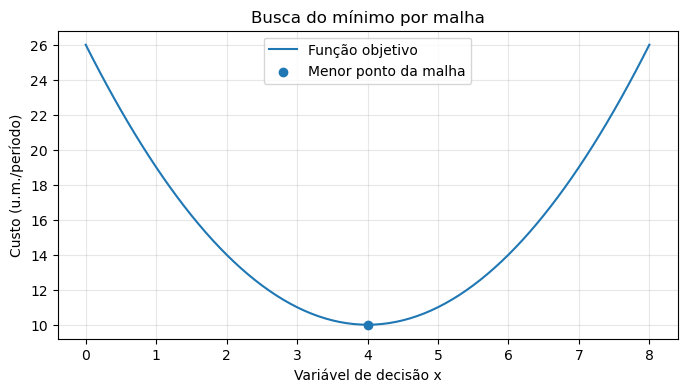

Melhor ponto: 4.0 ; custo: 10.0


In [3]:
x_malha=np.linspace(0,8,81)
C_malha=custo_quadratico(x_malha)
indice=np.argmin(C_malha)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(x_malha,C_malha,label='Função objetivo')
ax.scatter(x_malha[indice],C_malha[indice],label='Menor ponto da malha',zorder=3)
ax.set(xlabel='Variável de decisão x',ylabel='Custo (u.m./período)',title='Busca do mínimo por malha')
ax.grid(alpha=.3);ax.legend();plt.show()
print('Melhor ponto:',x_malha[indice],'; custo:',C_malha[indice])

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Derivadas e condições de primeira ordem</div>

**Condições necessárias e suficientes.** Para um ótimo interior de uma função diferenciável, $f'(x^*)=0$ é uma condição necessária. Se $f''(x^*)>0$, temos um mínimo local estrito. Em problemas com limites, o mínimo também pode ocorrer em uma extremidade.

Por exemplo, para $C(x)=(x-4)^2+10$ e $0\leq x\leq 3$, o ponto estacionário $x=4$ é inviável. Nesse intervalo, o mínimo ocorre em $x=3$, com custo $11$.

In [4]:
candidatos=np.array([0.,3.])
melhor=candidatos[np.argmin(custo_quadratico(candidatos))]
print(f'Mínimo com limite x <= 3: x={melhor:.1f}, C={custo_quadratico(melhor):.1f}')

Mínimo com limite x <= 3: x=3.0, C=11.0


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Método da seção áurea implementado em Python</div>

**Seção áurea — algoritmo antes da biblioteca.** Quando a função é unimodal em $[a,b]$, a seção áurea reduz sucessivamente o intervalo de busca sem exigir derivadas. Seja $\rho=(\sqrt5-1)/2$. Calculamos dois pontos internos $c=b-\rho(b-a)$ e $d=a+\rho(b-a)$, descartando a parte do intervalo que não pode conter o mínimo de uma função unimodal.

O critério de parada pode ser a largura $b-a<\varepsilon$. Esse algoritmo não garante o mínimo global de uma função multimodal.

In [5]:
def secao_aurea(f,a,b,tol=1e-8,max_iter=1000):
    if not (np.isfinite(a) and np.isfinite(b) and a<b and tol>0 and max_iter>0):
        raise ValueError('Intervalo ou tolerância inválidos.')
    rho=(np.sqrt(5)-1)/2
    c=b-rho*(b-a); d=a+rho*(b-a)
    fc=f(c);fd=f(d)
    for k in range(max_iter):
        if b-a<tol:break
        if fc<fd:
            b,d,fd=d,c,fc
            c=b-rho*(b-a);fc=f(c)
        else:
            a,c,fc=c,d,fd
            d=a+rho*(b-a);fd=f(d)
    x=(a+b)/2
    return x,f(x),k+1,b-a
x_aurea,c_aurea,it_aurea,largura=secao_aurea(custo_quadratico,0,8)
print(f'x={x_aurea:.8f}; C={c_aurea:.8f}; iterações={it_aurea}; intervalo={largura:.2e}')
assert np.isclose(x_aurea,4,atol=1e-5)

x=4.00000003; C=10.00000000; iterações=44; intervalo=8.25e-09


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Otimização com scipy.optimize.minimize_scalar</div>

**Bibliotecas prontas como etapa final.** O `minimize_scalar` do SciPy permite resolver problemas unidimensionais limitados. Depois de compreender a derivada, a malha e a seção áurea, podemos comparar o resultado com um método consolidado.

O retorno inclui informações sobre convergência. Em aplicações reais, a mensagem do algoritmo, a viabilidade e a coerência física devem ser verificadas antes de aceitar o resultado.

In [6]:
resultado=minimize_scalar(custo_quadratico,bounds=(0,8),method='bounded')
if not resultado.success:raise RuntimeError(resultado.message)
print(f'SciPy: x={resultado.x:.8f}; C={resultado.fun:.8f}')
print(f'Diferença para o ótimo analítico: {abs(resultado.x-4):.2e}')

SciPy: x=4.00000000; C=10.00000000
Diferença para o ótimo analítico: 0.00e+00


<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Otimização de uma mistura de matérias-primas</div>

**Mistura de matérias-primas.** Uma corrente de 100 kg/h é preparada com dois insumos, A e B. Se $x_A$ e $x_B$ são suas vazões mássicas, a conservação de massa impõe

$$x_A+x_B=100.$$

Suponha custos de 5 e 3 u.m./kg, respectivamente. O custo horário é $C=5x_A+3x_B$. Se a especificação exige ao menos 40 kg/h de A, então $x_A\geq40$. Substituindo $x_B=100-x_A$, temos $C=300+2x_A$. O menor custo viável ocorre em $x_A=40$ e $x_B=60$ kg/h, com $C=380$ u.m./h.

A especificação é uma hipótese didática; uma mistura real exigiria um modelo de propriedades e composição.

A=40 kg/h; B=60 kg/h; custo=380 u.m./h


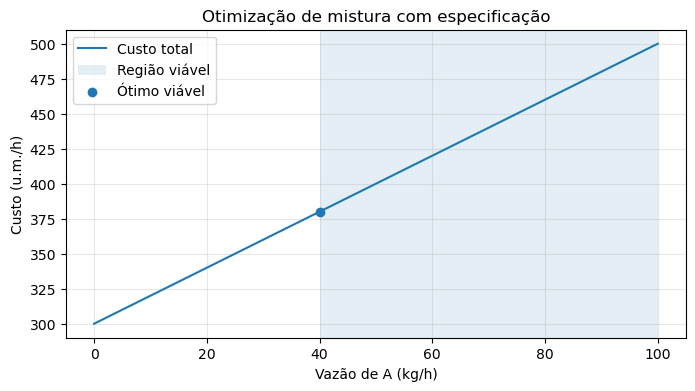

In [7]:
xA=np.linspace(0,100,201)
custo=5*xA+3*(100-xA)
viavel=xA>=40
indice=np.argmin(np.where(viavel,custo,np.inf))
print(f'A={xA[indice]:.0f} kg/h; B={100-xA[indice]:.0f} kg/h; custo={custo[indice]:.0f} u.m./h')
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(xA,custo,label='Custo total')
ax.axvspan(40,100,alpha=.12,label='Região viável')
ax.scatter(xA[indice],custo[indice],zorder=3,label='Ótimo viável')
ax.set(xlabel='Vazão de A (kg/h)',ylabel='Custo (u.m./h)',title='Otimização de mistura com especificação')
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Restrições de desigualdade e região viável</div>

**Restrições de desigualdade.** A região viável pode ser representada por expressões como $x_A\geq40$, $x_B\geq0$ e $x_A+x_B=100$. É importante diferenciar uma igualdade, que deve ser satisfeita, de uma desigualdade, que pode estar ativa ou folgada no ótimo.

No exemplo, a condição $x_A\geq40$ é **ativa**, pois $x_A=40$. O limite $x_B\geq0$ não é ativo, pois $x_B=60>0$.

In [8]:
solucao=np.array([40.,60.])
print('Resíduo do balanço:',solucao.sum()-100,'kg/h')
print('Folga da exigência de A:',solucao[0]-40,'kg/h')
print('Folga da não negatividade de B:',solucao[1],'kg/h')

Resíduo do balanço: 0.0 kg/h
Folga da exigência de A: 0.0 kg/h
Folga da não negatividade de B: 60.0 kg/h


<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Otimização de duas variáveis: interpretação geométrica</div>

**Duas variáveis de decisão.** Considere o custo adimensional

$$f(x,y)=(x-2)^2+2(y-3)^2+5.$$

O gradiente é $\nabla f=(2(x-2),4(y-3))$. A condição $\nabla f=0$ fornece $(x^*,y^*)=(2,3)$. A matriz Hessiana é diagonal, com elementos 2 e 4, ambos positivos: portanto, a função é estritamente convexa e o ponto é o mínimo global sem restrições.

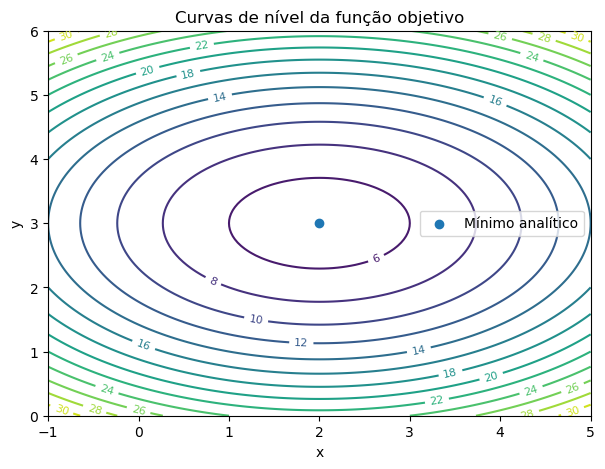

In [9]:
def objetivo_2d(v):
    x,y=v
    return (x-2)**2+2*(y-3)**2+5
X,Y=np.meshgrid(np.linspace(-1,5,121),np.linspace(0,6,121))
Z=(X-2)**2+2*(Y-3)**2+5
fig,ax=plt.subplots(figsize=(7,5))
cont=ax.contour(X,Y,Z,levels=14)
ax.clabel(cont,inline=True,fontsize=8)
ax.scatter([2],[3],label='Mínimo analítico')
ax.set(xlabel='x',ylabel='y',title='Curvas de nível da função objetivo')
ax.legend();plt.show()

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Gradiente e método da descida mais íngreme</div>

**Descida mais íngreme.** Um método iterativo usa o gradiente para indicar uma direção de redução da função:

$$\mathbf{x}_{k+1}=\mathbf{x}_k-\alpha\nabla f(\mathbf{x}_k).$$

O parâmetro $\alpha>0$ é o tamanho do passo. Para a função anterior, $\nabla f=(2(x-2),4(y-3))$. A escolha do passo influencia a estabilidade e a velocidade de convergência; não há um valor universal adequado a todos os problemas.

Ponto final: [2. 3.]; f=5.000000


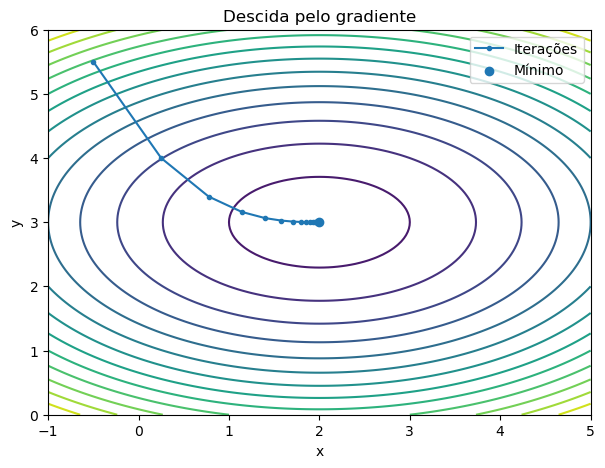

In [10]:
def gradiente_2d(v):
    x,y=v
    return np.array([2*(x-2),4*(y-3)],dtype=float)
ponto=np.array([-0.5,5.5]);trajetoria=[ponto.copy()]
alpha=0.15
for _ in range(60):
    ponto=ponto-alpha*gradiente_2d(ponto)
    trajetoria.append(ponto.copy())
trajetoria=np.array(trajetoria)
print(f'Ponto final: {trajetoria[-1]}; f={objetivo_2d(trajetoria[-1]):.6f}')
fig,ax=plt.subplots(figsize=(7,5))
ax.contour(X,Y,Z,levels=14)
ax.plot(trajetoria[:,0],trajetoria[:,1],'o-',markersize=3,label='Iterações')
ax.scatter([2],[3],label='Mínimo')
ax.set(xlabel='x',ylabel='y',title='Descida pelo gradiente')
ax.legend();plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Restrições ativas e multiplicadores de Lagrange</div>

**Multiplicadores de Lagrange.** Para minimizar $f(x,y)=x^2+y^2$ sujeito a $x+y=10$, construímos

$$\mathcal{L}=x^2+y^2+\lambda(x+y-10).$$

As condições de estacionariedade são $2x+\lambda=0$, $2y+\lambda=0$ e $x+y=10$. Logo, $x=y=5$, $\lambda=-10$ e $f^*=50$. O método incorpora a restrição de igualdade ao sistema de equações; a interpretação econômica do multiplicador depende da convenção de sinais e das unidades.

In [11]:
x_lag=y_lag=5.0
print('Solução:',(x_lag,y_lag),'objetivo:',x_lag**2+y_lag**2)
assert np.isclose(x_lag+y_lag,10)

Solução: (5.0, 5.0) objetivo: 50.0


<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Otimização numérica com SLSQP</div>

**Restrições no SciPy.** O algoritmo SLSQP permite tratar igualdades, desigualdades e limites. No SciPy, uma restrição de desigualdade definida no formato de dicionário `{'type': 'ineq', 'fun': ...}` exige que a função seja **não negativa**.

Resolveremos o problema da mistura diretamente em duas variáveis, com balanço de massa e vazão mínima de A. A solução numérica deve ser comparada com a dedução manual.


**O que é SLSQP?**

SLSQP é a sigla de *Sequential Least Squares Programming*, que pode ser traduzida como **Programação Sequencial por Mínimos Quadrados**. Trata-se de um algoritmo de otimização numérica utilizado para determinar os valores ótimos das variáveis de decisão, respeitando as restrições impostas ao problema.

Em Engenharia Química, sua utilização é particularmente interessante porque os processos industriais frequentemente apresentam limitações de vazão, temperatura, pressão, composição e capacidade operacional dos equipamentos.

Matematicamente, o problema pode ser representado por:

$$
\min_{\mathbf{x}} f(\mathbf{x})
$$

sujeito a:

$$
g_i(\mathbf{x})\geq 0
$$

$$
h_j(\mathbf{x})=0
$$

e aos limites:

$$
x_{k,\min}\leq x_k\leq x_{k,\max}.
$$

O princípio do SLSQP consiste em construir, a cada iteração, uma aproximação quadrática do problema de otimização, acompanhada de aproximações lineares das restrições. Dessa maneira, o algoritmo resolve sucessivamente subproblemas mais simples, procurando aproximar-se de uma solução que satisfaça as condições de otimalidade.

No Python, o algoritmo é selecionado pela instrução:

`method="SLSQP"`

É importante compreender que essa instrução não representa a formulação matemática do problema. Ela apenas informa ao SciPy qual algoritmo deverá ser utilizado para resolver o problema previamente definido pelo engenheiro.

**Uma limitação importante:** o SLSQP é um método de otimização local. Portanto, em problemas não convexos, a solução encontrada pode depender da estimativa inicial e não corresponder necessariamente ao ótimo global.

No exemplo de mistura desenvolvido a seguir, utilizaremos o SLSQP para determinar numericamente as variáveis ótimas, respeitando as restrições de balanço de massa e de vazão mínima estabelecidas anteriormente.

In [12]:
def custo_mistura(v):
    return 5*v[0]+3*v[1]
restricoes=[{'type':'eq','fun':lambda v:v[0]+v[1]-100},
            {'type':'ineq','fun':lambda v:v[0]-40}]
resultado_mix=minimize(custo_mistura,[50.,50.],method='SLSQP',
                       bounds=[(0,100),(0,100)],constraints=restricoes,
                       options={'ftol':1e-10,'maxiter':1000})
if not resultado_mix.success:raise RuntimeError(resultado_mix.message)
print('Vazões (kg/h):',np.round(resultado_mix.x,5))
print(f'Custo mínimo: {resultado_mix.fun:.3f} u.m./h')
assert np.allclose(resultado_mix.x,[40,60],atol=1e-4)

Vazões (kg/h): [40. 60.]
Custo mínimo: 380.000 u.m./h


<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Programação linear de planejamento de produção</div>

**Planejamento de produção.** Uma unidade produz dois produtos, A e B, com margens de contribuição de 30 e 20 u.m. por unidade. A produção utiliza duas capacidades limitadas:

$$2x_A+x_B\leq100,\qquad x_A+2x_B\leq80,\qquad x_A,x_B\geq0.$$

Desejamos maximizar $L=30x_A+20x_B$. No SciPy, `linprog` minimiza, então fornecemos $-L$. A interseção das duas restrições ativas satisfaz $2x_A+x_B=100$ e $x_A+2x_B=80$, resultando em $x_A=40$ e $x_B=20$. O lucro é $1600$ u.m. no período definido.

In [13]:
res_lp=linprog(c=[-30,-20],A_ub=[[2,1],[1,2]],b_ub=[100,80],
               bounds=[(0,None),(0,None)],method='highs')
if not res_lp.success:raise RuntimeError(res_lp.message)
print('Produção ótima:',res_lp.x)
print('Margem máxima:',-res_lp.fun,'u.m./período')
assert np.allclose(res_lp.x,[40,20],atol=1e-7)

Produção ótima: [40. 20.]
Margem máxima: 1600.0 u.m./período


<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Análise de sensibilidade e robustez</div>

**Análise de sensibilidade.** Um resultado ótimo é condicionado pelos parâmetros do modelo. Se o custo de A aumentar, a solução da mistura pode permanecer no limite mínimo de A; se a especificação mudar, o ponto ótimo e o custo mudam.

Vamos variar a vazão mínima exigida de A, mantendo os demais parâmetros. Para uma exigência $a$, o custo mínimo é $C^*(a)=5a+3(100-a)=300+2a$ u.m./h, para $0\leq a\leq100$. A inclinação $2$ u.m./(kg/h) quantifica o aumento de custo por unidade adicional exigida de A, dentro desse modelo.

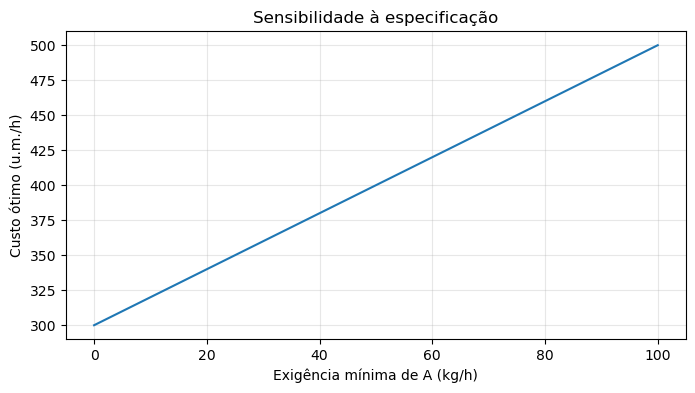

Custo para 40 kg/h: 380 u.m./h


In [14]:
a_min=np.linspace(0,100,101)
custo_minimo=300+2*a_min
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(a_min,custo_minimo)
ax.set(xlabel='Exigência mínima de A (kg/h)',ylabel='Custo ótimo (u.m./h)',title='Sensibilidade à especificação')
ax.grid(alpha=.3);plt.show()
print('Custo para 40 kg/h:',300+2*40,'u.m./h')

<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Estudo de caso: dimensionamento econômico de tubulação</div>

**Estudo de caso — diâmetro econômico de uma tubulação.** Para vazão volumétrica fixa $Q$, a velocidade média é $v=4Q/(\pi D^2)$. Em escoamento turbulento com fator de atrito aproximadamente constante, a perda de carga de Darcy–Weisbach varia aproximadamente com $D^{-5}$. A potência de bombeamento acompanha essa tendência sob hipóteses simplificadoras.

Considere um custo anualizado de tubulação proporcional ao diâmetro e um custo anual de bombeamento inversamente proporcional à quinta potência:

$$C(D)=aD+\frac{b}{D^5},\qquad D>0.$$

Aqui $D$ está em metros, $a=1000$ u.m./(ano·m) e $b=0{,}01$ u.m.·m$^5$/ano. Esses coeficientes são **hipotéticos** e não substituem custos reais. A derivada é $C'(D)=a-5b/D^6$, logo

$$D^*=\left(\frac{5b}{a}\right)^{1/6}.$$

O modelo ilustra a competição entre investimento e consumo energético, mas não incorpora diâmetros comerciais, regimes de escoamento variáveis, NPSH, materiais ou critérios de segurança.

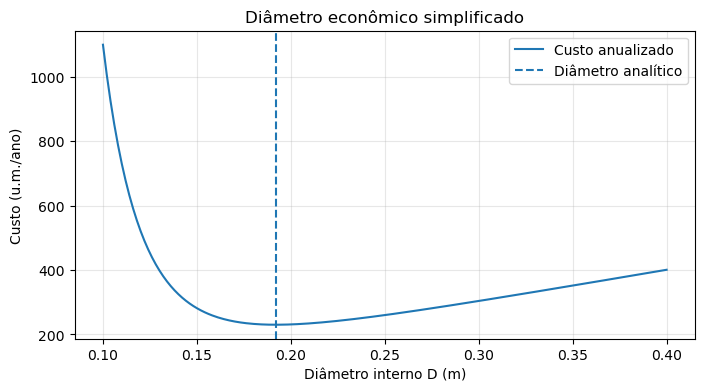

D analítico=0.19194 m; D SciPy=0.19194 m


In [15]:
a=1000.0
bcoef=0.01
def custo_tubo(D):
    D=np.asarray(D)
    return a*D+bcoef/D**5
D_analitico=(5*bcoef/a)**(1/6)
res_tubo=minimize_scalar(custo_tubo,bounds=(0.10,0.40),method='bounded')
if not res_tubo.success:raise RuntimeError(res_tubo.message)
D=np.linspace(0.10,0.40,300)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(D,custo_tubo(D),label='Custo anualizado')
ax.axvline(D_analitico,linestyle='--',label='Diâmetro analítico')
ax.set(xlabel='Diâmetro interno D (m)',ylabel='Custo (u.m./ano)',title='Diâmetro econômico simplificado')
ax.grid(alpha=.3);ax.legend();plt.show()
print(f'D analítico={D_analitico:.5f} m; D SciPy={res_tubo.x:.5f} m')
assert np.isclose(D_analitico,res_tubo.x,atol=1e-4)

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Validação, limites e interpretação dos resultados</div>

**Verificação de engenharia.** Um resultado numérico só deve ser aceito após verificar: convergência do algoritmo, satisfação das restrições, unidades, limites físicos, coerência do modelo e sensibilidade às hipóteses. Um valor mínimo pode ser matematicamente correto e operacionalmente inviável.

No caso da tubulação, a solução contínua precisaria ser comparada com diâmetros comerciais e reavaliada por um modelo hidráulico adequado. Na mistura, a especificação de qualidade foi substituída por um limite simples de vazão; esse limite deve ser justificado por dados físicos em um projeto real.

`assert` é útil para testes didáticos, mas não deve substituir validações obrigatórias de entrada ou mecanismos de segurança.

In [16]:
assert np.isclose(custo_quadratico(4),10)
assert np.isclose(resultado_mix.x.sum(),100,atol=1e-6)
assert resultado_mix.x[0]>=40-1e-6
assert np.all(np.array([[2,1],[1,2]])@res_lp.x <= np.array([100,80])+1e-6)
assert 0.10<=res_tubo.x<=0.40
print('Verificações numéricas e de viabilidade concluídas.')

Verificações numéricas e de viabilidade concluídas.


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Exercícios de consolidação</div>

**Exercício 1 — Formulação.** Defina variáveis de decisão, objetivo e restrições para minimizar o consumo de vapor de um trocador de calor que precisa atingir uma temperatura mínima de saída.

**Exercício 2 — Solução analítica.** Minimize $f(x)=(x-6)^2+4$ em $0\leq x\leq10$. Resolva por derivadas e compare com uma malha numérica.

**Exercício 3 — Limites.** Resolva o exercício anterior impondo $0\leq x\leq4$. Explique por que o mínimo ocorre na fronteira.

**Exercício 4 — Algoritmo.** Utilize a seção áurea para minimizar $f(x)=(x-3)^2+2$ em $[0,8]$. Varie a tolerância e observe o número de iterações.

**Exercício 5 — Mistura.** Uma corrente de 200 kg/h deve conter ao menos 70 kg/h do insumo A. Os custos são 6 e 4 u.m./kg para A e B. Formule o problema, resolva manualmente e com SLSQP.

**Exercício 6 — Duas variáveis.** Minimize $f(x,y)=(x-1)^2+3(y-2)^2$ e interprete o gradiente e a Hessiana.

**Exercício 7 — Lagrange.** Minimize $x^2+4y^2$ sujeito a $x+y=12$, mostrando cada equação de estacionariedade.

**Exercício 8 — Programação linear.** Modifique as margens dos produtos do exemplo de planejamento para 25 e 35 u.m. por unidade e explique a mudança do plano ótimo.

**Exercício 9 — Sensibilidade.** Varie a exigência mínima de A no exemplo de mistura de 20 a 80 kg/h. Calcule o aumento de custo e interprete sua origem.

**Desafio integrador.** Pesquise quais hipóteses do modelo de diâmetro econômico precisariam ser revistas para uma instalação real e explique como incluir restrições de velocidade, pressão e diâmetros comerciais antes de programar a otimização.

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões</div>

A otimização de processos exige formular com precisão **o que pode variar, o que se deseja melhorar e quais condições não podem ser violadas**. Neste notebook, começamos com soluções analíticas e algoritmos explícitos e, apenas depois, utilizamos ferramentas de otimização do SciPy.

Os estudos de mistura, planejamento de produção e dimensionamento econômico mostram que uma solução ótima deve ser interpretada em conjunto com a física, as restrições, as unidades e a validade das hipóteses. Essa postura prepara o estudante para problemas de Engenharia mais complexos, nos quais simulação e otimização trabalham de forma integrada.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>